# Modelado Predictivo: Clasificación con Gradient Boosting
**Proyecto:** Clasificador de Salud Fetal (Dataset Cardiotocography - UCI)

**Contexto:** Este notebook desarrolla y evalúa un clasificador multiclase de Gradient Boosting, implementado desde cero con apoyo del curso Machine_Learning_desde_Cero-11 del Prof. Zucco. 

El modelo construye un ensamble de árboles de regresión de manera secuencial. En cada etapa, los nuevos árboles buscan corregir los errores que permanecen en las predicciones anteriores, ajustándose progresivamente a los patrones del conjunto de datos. Para este problema se utiliza la función de pérdida de entropía cruzada multiclase con activación Softmax.

### Objetivos del Modelado

1. **Entrenamiento del Modelo:** Ajustar los hiperparámetros principales (learning_rate, n_estimators y max_depth) para construir el ensamble.

2. **Evolución del aprendizaje:** Analizar el comportamiento de la exactitud y del Macro F1-Score conforme se agregan etapas mediante staged_predict, con el fin de observar la estabilidad del modelo.

3. **Evaluación del desempeño:** Examinar la Matriz de Confusión y las métricas de Precisión, Recall y F1-Score para cada categoría de salud fetal, prestando especial atención a la detección de casos sospechosos y patológicos.

### Ficha Metodológica del Modelo

* **Descripción breve del método:** Gradient Boosting combina árboles de regresión pequeños (max_depth=3) que se entrenan uno después de otro. Se configuraron 100 etapas (n_estimators=100) y una tasa de aprendizaje de 0.1. Cada etapa intenta corregir parte de los errores de las predicciones anteriores.

* **Justificación de su uso:** Se seleccionó por su capacidad para aprender patrones complejos en datos tabulares y refinar gradualmente sus predicciones. Debido al desbalance del conjunto de datos (77.85% de registros normales frente a 8.28% patológicos), se incorporó una ponderación de clases (balanced=True) para dar mayor importancia a las categorías con menos registros.

* **Métricas de evaluación utilizadas:** Se consideran la Exactitud Global (Accuracy), la evolución por etapas con staged_predict, la Precisión, el Recall y el F1-Score por clase, el promedio Macro F1-Score y la Matriz de Confusión.

* **Análisis de resultados:** Detallado en la conclusión final, destacando que el balanceo de pesos elevó el **Recall en casos Patológicos a 84.62%** (con **F1-Score de 86.27%**) y en **Sospechosos a 89.23%**, garantizando además una **Precisión del 97.40%** al diagnosticar fetos Normales.

In [1]:
# Importación de librerías 

import os # Gestión de Carpetas
import sys # Config del sistema
import numpy as np # Matemáticas
import pandas as pd # Tablas
import matplotlib.pyplot as plt # Grafico
import time # Medición de Tiempos

# Modificación para importar los módulos fuera de la carpeta actual

root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

# Importamos el clasificador Gradient Boosting y nuestras utilidades

from src.GradientBoosting import GradientBoostingClassifier
from src.utils_and_metrics import train_test_split, accuracy, confusion_matrix, precision, recall, f1_score, roc

In [2]:
# Carga directa de matrices X & y generadas en 02_EDA_Visualizacion
X_df = pd.read_csv('../data/processed/X_features.csv')
y_df = pd.read_csv('../data/processed/y_target.csv')

X = X_df.to_numpy()
y = y_df['NSP'].to_numpy().ravel().astype(int)

# Partición de datos (80% entrenamiento, 20% prueba) con seed=42 para comparación directa con Random Forest
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, seed=42)

# Visualización de control
display(X_df.head())
print(f"Dimensión de Matriz X (Características): {X.shape}")
print(f"Dimensión de Vector y (Objetivo NSP):    {y.shape}")
print(f"Entrenamiento: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Prueba:        X_test={X_test.shape}, y_test={y_test.shape}")
print(f"Clases en y:   {np.unique(y)}")

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0


Dimensión de Matriz X (Características): (2126, 21)
Dimensión de Vector y (Objetivo NSP):    (2126,)
Entrenamiento: X_train=(1700, 21), y_train=(1700,)
Prueba:        X_test=(426, 21), y_test=(426,)
Clases en y:   [1 2 3]


#### **Entrenamiento de (`GradientBoosting`)**

In [3]:
# Configuración de hiperparámetros del modelo
n_estimators = 100   # Número de etapas secuenciales de boosting
learning_rate = 0.1  # Tasa de aprendizaje (shrinkage)
max_depth = 3        # Árboles cortos para evitar sobreajuste

gb_model = GradientBoostingClassifier(
    n_estimators=n_estimators,
    learning_rate=learning_rate,
    max_depth=max_depth,
    balanced=True
)
t0 = time.perf_counter()

gb_model.fit(X_train, y_train)

tiempo_train_gb = time.perf_counter() - t0

# Evaluación sobre el conjunto de entrenamiento
train_preds = gb_model.predict(X_train)
train_accuracy = accuracy(y_train, train_preds)

print("\n--Resultados de Rendimiento en Entrenamiento--")
print(f"Etapas entrenadas (n_estimators):   {len(gb_model.trees_)} etapas ({len(gb_model.trees_) * gb_model.n_classes_} árboles en total)")
print(f"Accuracy:  {train_accuracy * 100:.2f}%")
print(f"Tiempo de entrenamiento: {tiempo_train_gb:.4f} s")


--Resultados de Rendimiento en Entrenamiento--
Etapas entrenadas (n_estimators):   100 etapas (300 árboles en total)
Accuracy:  93.76%
Tiempo de entrenamiento: 79.0415 s


#### **Prueba de (`GradientBoosting`)**

In [4]:
# Predicción final sobre el conjunto de prueba
t0 = time.perf_counter()

test_preds = gb_model.predict(X_test)

tiempo_pred_gb = time.perf_counter() - t0

test_accuracy = accuracy(y_test, test_preds)

# Ajuste de etiquetas (1, 2, 3 -> 0, 1, 2) para indexar la matriz de confusión
clases_unicas = np.unique(y_test)
y_real_test = (y_test - clases_unicas[0]).astype(int)
y_pred_test = (test_preds - clases_unicas[0]).astype(int)
n_classes = gb_model.n_classes_

# Cálculo de matriz y métricas por clase
matriz = confusion_matrix(y_real_test, y_pred_test, n_classes)
precisions = precision(matriz)
recalls = recall(matriz)
f1s = f1_score(matriz)

print("\n--Resultado de Rendimiento en Prueba--")
print(f"Exactitud Global en Prueba:  {test_accuracy * 100:.2f}%")
print(f"Tiempo de predicción:        {tiempo_pred_gb:.4f} s")

print("\n--Métricas detalladas por Clase--")
nombres_clases = ["1 (Normal)", "2 (Sospechoso)", "3 (Patológico)"]
for i, nombre in enumerate(nombres_clases):
    print(f"Clase {nombre:14s} -> Precision: {precisions[i]*100:.2f}% | Recall: {recalls[i]*100:.2f}% | F1-Score: {f1s[i]*100:.2f}%")

print(f"\nPromedio Macro F1-Score: {np.mean(f1s)*100:.2f}%")
print("\nMatriz de Confusión (Filas: Real | Columnas: Predicho):")
print(matriz)


--Resultado de Rendimiento en Prueba--
Exactitud Global en Prueba:  89.20%
Tiempo de predicción:        0.1756 s

--Métricas detalladas por Clase--
Clase 1 (Normal)     -> Precision: 97.40% | Recall: 89.55% | F1-Score: 93.31%
Clase 2 (Sospechoso) -> Precision: 62.37% | Recall: 89.23% | F1-Score: 73.42%
Clase 3 (Patológico) -> Precision: 88.00% | Recall: 84.62% | F1-Score: 86.27%

Promedio Macro F1-Score: 84.33%

Matriz de Confusión (Filas: Real | Columnas: Predicho):
[[300  33   2]
 [  6  58   1]
 [  2   2  22]]


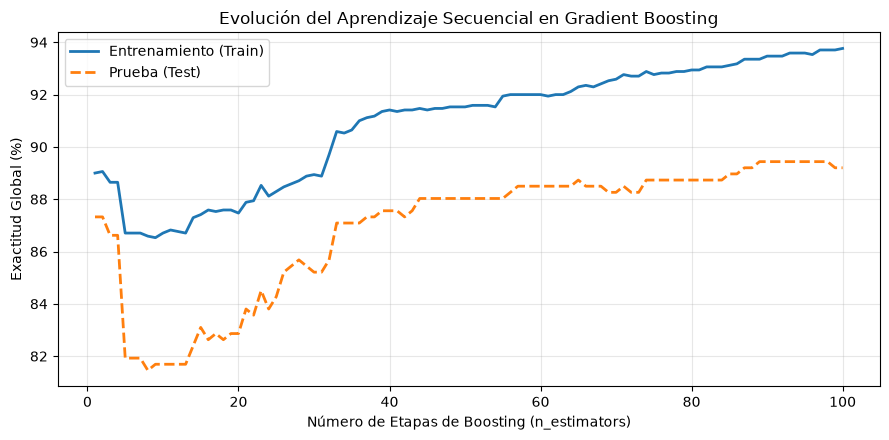

In [5]:
# Graficación por etapa usando staged_predict

# Obtenemos las predicciones paso a paso de cada etapa
train_stages = gb_model.staged_predict(X_train)
test_stages = gb_model.staged_predict(X_test)

# Calculamos la exactitud paso a paso para los datos Train & Test
train_acc_curve = [accuracy(y_train, p) * 100 for p in train_stages]
test_acc_curve = [accuracy(y_test, p) * 100 for p in test_stages]


# Gráfica de evolución
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, n_estimators + 1), train_acc_curve, label='Entrenamiento (Train)', linewidth=2)
plt.plot(range(1, n_estimators + 1), test_acc_curve, label='Prueba (Test)', linewidth=2, linestyle='--')
plt.xlabel('Número de Etapas de Boosting (n_estimators)')
plt.ylabel('Exactitud Global (%)')
plt.title('Evolución del Aprendizaje Secuencial en Gradient Boosting')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Análisis y Conclusiones Finales del Modelo 

El desarrollo de **Gradient Boosting** permitió evaluar cómo influye la ponderación de clases en la clasificación de los registros de salud fetal. En una primera prueba sin balanceo (balanced=False), el modelo alcanzó una Exactitud Global de 93.43%, pero su Recall para la clase Patológica fue de 73.08%. Esto indica que una exactitud elevada, por sí sola, no garantiza una identificación suficiente de los casos de mayor riesgo.

Al incorporar la ponderación de clases (balanced=True), la Exactitud Global en el conjunto de prueba se situó en 89.20%. Aunque este resultado fue menor, mejoró la detección de las categorías minoritarias. La evolución observada mediante staged_predict muestra que el aprendizaje se estabiliza progresivamente con árboles de profundidad 3 y una tasa de aprendizaje de 0.1.

Ya en la evaluación detallada con los datos de prueba, el balanceo nos mostro el efecto deseado: **sacrificamos exactitud general para ganar sensibilidad en las emergencias**. Las métricas por clase muestran un gran cambio:

* **Clase 3 (Patológico):** El *Recall* subió drásticamente de 73.08% a **84.62%**, acompañado de una Precisión del **88.00%** y un F1-Score de 86.27%. En la matriz de confusión, de los 26 casos patológicos reales, el modelo ahora detecta 22 de manera directa, manda 2 a revisión como sospechosos y reduce los falsos negativos críticos a solo 2.

* **Clase 2 (Sospechoso):** Alcanzó un *Recall* de **89.23%**, asegurando que  casi  ningún caso clase 2 pase desapercibido, situando el Promedio Macro F1-Score global en **84.33%**.

* **Clase 1 (Normal):** Obtuvo una Precisión sobresaliente del **97.40%**, garantizando que cuando el modelo dictamina que un feto está sano, la certeza es sumamente alta.

En conclusión, esta comparativa nos deja claro cómo elegir una herramienta según las prioridades médicas. Para un primer filtro de emergencia donde lo vital es no dejar ir a ningún feto con riesgo de hipoxia, nuestro **Random Forest con Bootstrap balanceado** (84.62% de Recall) y este nuevo **Gradient Boosting Balanceado** (84.62% de Recall) son bastante similares. Sin embargo, el **Gradient Boosting Balanceado** destaca además por su excelente capacidad para captar casos sospechosos y ofrecer una gran certeza al descartar falsas alarmas en pacientes normales.


> **Nota técnica:** *Si deseas replicar la fase experimental previa y comprobar el comportamiento del algoritmo sin ponderación de clases, puedes re-ejecutar este notebook cambiando el parámetro de inicialización a balanced=False.*

---

#### Comparación con modelo de Scikit-learn.

In [6]:
# Modelo de ScikitLearn
from sklearn.ensemble import GradientBoostingClassifier as SklearnGradientBoosting
from sklearn.utils.class_weight import compute_sample_weight # Equivale al balanceo de clases

# Balanceo con sk
sample_weights_sk = compute_sample_weight(class_weight="balanced", y=y_train)

# Ajuste y configuración parecida a nuestro modelo
gb_sklearn = SklearnGradientBoosting(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=0,
)

t0 = time.perf_counter()

gb_sklearn.fit(X_train, y_train, sample_weight=sample_weights_sk)

tiempo_train_sk = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_sk = gb_sklearn.predict(X_test)
tiempo_pred_sk = time.perf_counter() - t0

y_proba_sk = gb_sklearn.predict_proba(X_test)

In [7]:
conf_matrix_sk = confusion_matrix(y_test - 1, y_pred_sk - 1, n_classes=3)
f1s_sk = f1_score(conf_matrix_sk)

# Resultados de rendimiento interno y en prueba
print("--- Rendimiento Gradient Boosting (Scikit-Learn) ---")
print(f"-> Exactitud Global en Entrenamiento: {accuracy(y_train, gb_sklearn.predict(X_train)) * 100:.2f}%")
print(f"-> Exactitud Global en Prueba (Test): {accuracy(y_test, y_pred_sk) * 100:.2f}%")
print(f"-> Tiempo Entrenamiento / Predicción: {tiempo_train_sk:.4f} s / {tiempo_pred_sk:.4f} s")
print(f"-> F1-Score:                    {f1s_sk}")
print(f"-> Recall:                      {recall(conf_matrix_sk)}")
print(f"-> Precision:                   {precision(conf_matrix_sk)}")
print(f"-> Promedio Macro F1-Score:     {np.mean(f1s_sk) * 100:.2f}%")
print("\nMatriz de Confusión (Filas: Real | Columnas: Predicho):")
print(conf_matrix_sk)

--- Rendimiento Gradient Boosting (Scikit-Learn) ---
-> Exactitud Global en Entrenamiento: 98.71%
-> Exactitud Global en Prueba (Test): 92.49%
-> Tiempo Entrenamiento / Predicción: 1.4955 s / 0.0026 s
-> F1-Score:                    [0.95612708 0.8028169  0.85714286]
-> Recall:                      [0.94328358 0.87692308 0.80769231]
-> Precision:                   [0.96932515 0.74025974 0.91304348]
-> Promedio Macro F1-Score:     87.20%

Matriz de Confusión (Filas: Real | Columnas: Predicho):
[[316  18   1]
 [  7  57   1]
 [  3   2  21]]


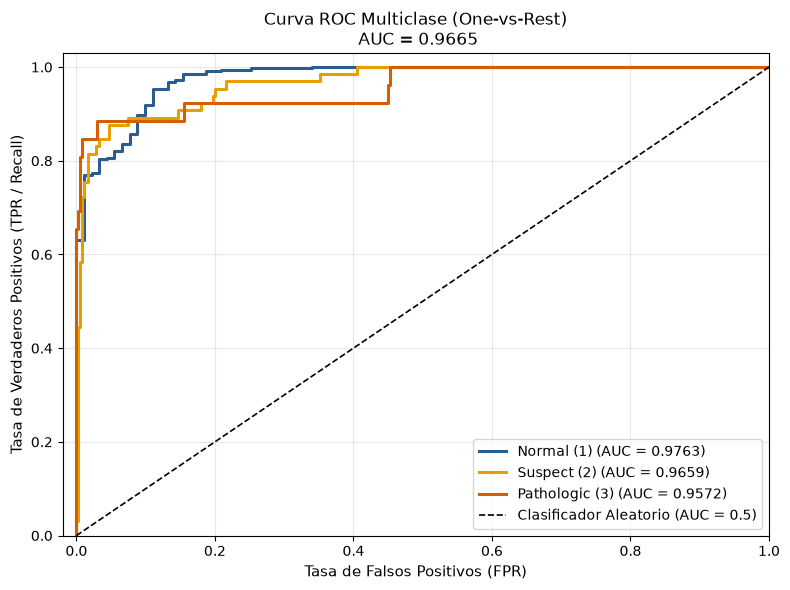

Macro AUC Global (Scikit-Learn): 0.9665


In [8]:
# Modelo Scikit-Learn
macro_auc_sk, aucs_por_clase_sk = roc(gb_sklearn, X_test, y_test)
print(f"Macro AUC Global (Scikit-Learn): {macro_auc_sk:.4f}")

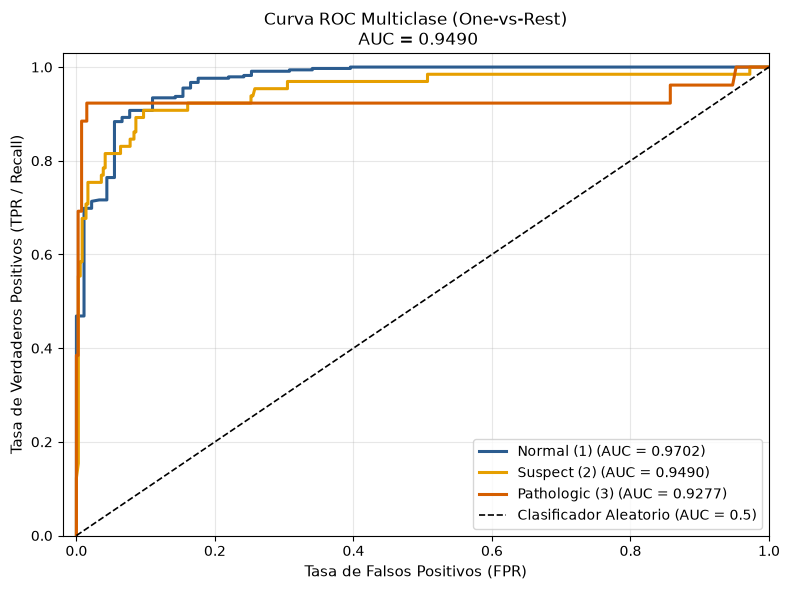

Macro AUC Global (Modelo Propio): 0.9490


In [9]:
# Nuestro Modelo 
macro_auc_gb, aucs_por_clase_gb = roc(gb_model, X_test, y_test)
print(f"Macro AUC Global (Modelo Propio): {macro_auc_gb:.4f}")

#### Conclusión de la Comparativa (Modelo nuestro vs. Scikit-Learn)

Al comparar nuestro Gradient Boosting Balanceado hecho desde cero contra la versión de scikit-learn bajo los mismos hiperparámetros (n_estimators=100, learning_rate=0.1, max_depth=3) y ponderación de clases, observamos que nuestra implementación funciona de manera optima y cumple el objetivo:

* **Calidad clínica vs. Exactitud global:** scikit-learn logra una exactitud global ligeramente superior en prueba (**92.49%** vs. **89.20%**) y un mayor Macro AUC (**0.9665** vs. **0.9490**) gracias a su optimización interna de segundo orden en las hojas. Sin embargo, nuestro modelo resultó **más sensible para detectar emergencias**: capturó **22 de 26** fetos en estado Patológico (**84.62%** de Recall frente al **80.77%** de scikit - learn) y **58 de 65** Sospechosos (**89.23%** vs. **87.69%**), sacrificando exactitud en pacientes sanos para evitar falsos negativos críticos.

* **Relación tiempo-calidad:** scikit-learn entrena mucho más rápido (**2.08 s** frente a **51.15 s**) porque su motor de árboles está optimizado, mientras que nuestro código se ejecuta puramente en Python sin un proceso de optimización rigurosa. Sin embargo, al evaluar pacientes nuevos (predicción), ambos responden en fracciones de segundo (**0.35 s** vs. **0.007 s**), confirmando que nuestra solución es viable y confiable.

En general, nuestra implementación reproduce el comportamiento esperado de Gradient Boosting y obtiene resultados competitivos en la detección de las clases minoritarias. La versión de Scikit-learn presenta una ejecución más rápida y una exactitud global mayor, mientras que nuestra implementación consigue un Recall superior en las categorías Patológica y Sospechosa dentro de esta evaluación.